In [2]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [8]:
data = pd.read_csv('../data/ecoflex/3_Trials_plus_skin_refs_BTVIZ_2025-10-08.csv')
meta = pd.read_csv('../data/ecoflex/ecoflex_table.csv')

In [17]:
data = data[[col for col in data.columns if col.startswith('data_')]]
print(data.shape)

sl = meta['Left boundary']
sr = meta['Right boundary']

(91092, 6)


In [21]:
# Select data segments based on left and right boundaries and calculate averages
result_data = []

# Iterate through each segment defined by sl and sr
for i in range(len(sl)):
    left_idx = int(sl.iloc[i])
    right_idx = int(sr.iloc[i])
    
    segment_data = data.iloc[left_idx:right_idx+1]  # +1 to include right boundary
    segment_avg = segment_data.mean(axis=0)
    result_data.append(segment_avg)

# Convert to DataFrame
result_df = pd.DataFrame(result_data)
print(f"\nResult shape: {result_df.shape}")
print(f"Result columns: {result_df.columns.tolist()}")
print(f"\nFirst 5 rows of averaged data:")
print(result_df.head())


Result shape: (39, 6)
Result columns: ['data_0', 'data_1', 'data_2', 'data_3', 'data_4', 'data_5']

First 5 rows of averaged data:
      data_0      data_1      data_2       data_3      data_4      data_5
0  71.672351  186.235079  565.785627   890.651644  526.626066  138.900122
1  85.357143  231.413866  687.159664  1092.567227  627.077731  159.586134
2  74.975824  195.116484  589.723077   939.408791  547.604396  141.287912
3  72.959603  189.221828  574.720057   917.944011  533.257264  140.606662
4  86.902893  238.741736  709.020661  1123.950413  651.638430  160.849174


In [27]:
# KISS: Create and display matrices of averaged measurements by skin/blood layer
# Group measurements by skin and blood layer combinations
meta_with_results = meta.copy()
for col in result_df.columns:
    meta_with_results[col] = result_df[col]

grouped = meta_with_results.groupby(['Skin layer', 'Blood layer'])[result_df.columns].mean()

# Get layer labels
skin_layers = sorted(meta['Skin layer'].unique())
blood_layers = sorted(meta['Blood layer'].unique())

# Create matrices for all channels
matrices = {}
for channel in result_df.columns:
    matrix = np.full((len(blood_layers), len(skin_layers)), np.nan)
    for (skin, blood), values in grouped.iterrows():
        matrix[blood_layers.index(blood), skin_layers.index(skin)] = values[channel]
    matrices[channel] = matrix

# Create 3D array and display summary
all_channels_matrix = np.stack(list(matrices.values()), axis=2)

print(f"Matrix dimensions: {len(blood_layers)} blood × {len(skin_layers)} skin × 6 channels")
print(f"Blood layers: {blood_layers}")
print(f"Skin layers: {skin_layers}")
print(f"3D matrix shape: {all_channels_matrix.shape}")
print(f"12 unique combinations processed from {len(result_df)} original measurements")

Matrix dimensions: 4 blood × 3 skin × 6 channels
Blood layers: ['R1:1B', 'R1:2B', 'R2:1B', 'none']
Skin layers: ['F', 'F1:1B', 'F2:1B']
3D matrix shape: (4, 3, 6)
12 unique combinations processed from 39 original measurements


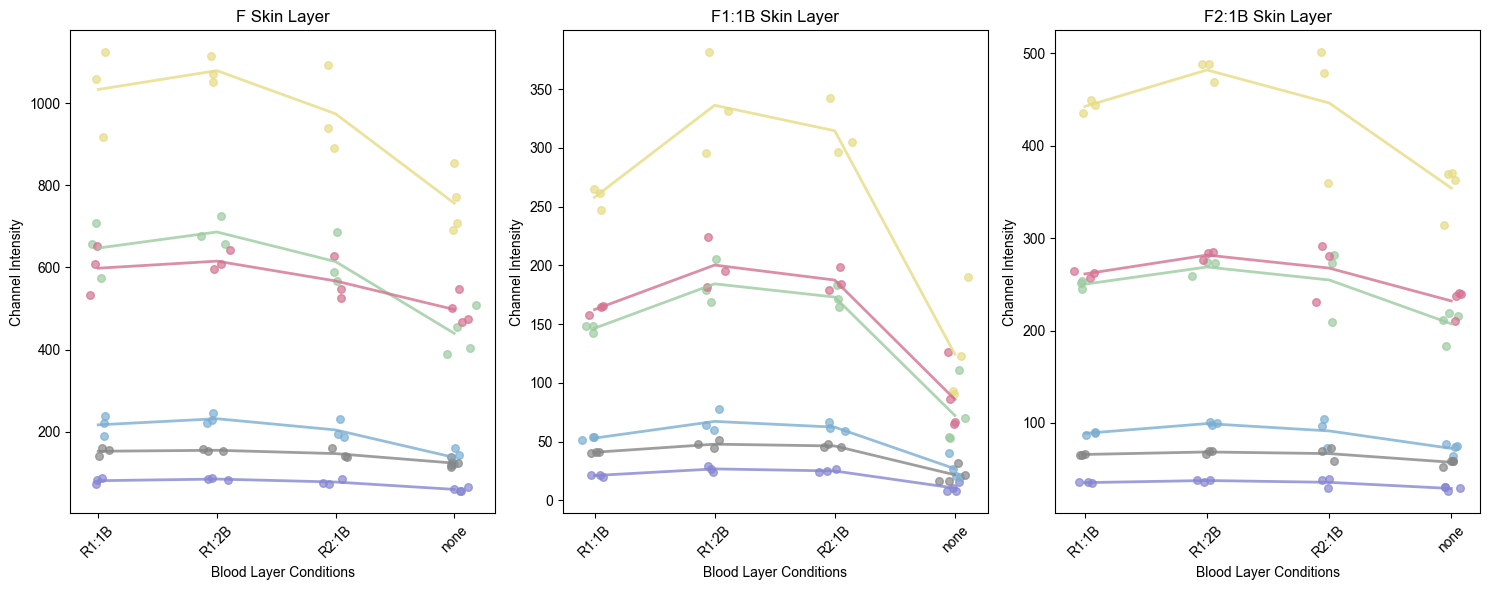

In [30]:
# Plot trends of six channels over trials for each skin condition
fig, axes = plt.subplots(1, len(skin_layers), figsize=(5*len(skin_layers), 6))
if len(skin_layers) == 1:
    axes = [axes]

# Prepare data for plotting - get individual trial data for each skin condition
for skin_idx, skin_layer in enumerate(skin_layers):
    ax = axes[skin_idx]
    
    # Get data for this skin layer across all blood conditions
    skin_data = meta_with_results[meta_with_results['Skin layer'] == skin_layer]
    
    # Plot each channel
    for channel_idx, channel in enumerate(result_df.columns):
        channel_num = channel.split('_')[1]
        
        # Get values for this channel across all blood conditions
        x_positions = []
        y_values = []
        blood_labels = []
        
        for blood_idx, blood_layer in enumerate(blood_layers):
            # Get trials for this specific skin-blood combination
            combo_data = skin_data[skin_data['Blood layer'] == blood_layer]
            if not combo_data.empty:
                values = combo_data[channel].values
                positions = [blood_idx] * len(values)
                x_positions.extend(positions)
                y_values.extend(values)
                blood_labels.extend([blood_layer] * len(values))
        
        # Plot with jittered x positions for visibility
        jitter = np.random.normal(0, 0.05, len(x_positions))
        x_jittered = np.array(x_positions) + jitter
        
        ax.scatter(x_jittered, y_values, alpha=0.7, color=colors[channel_idx], 
                  s=30, label=f'Channel {channel_num}')
        
        # Add trend line (mean values)
        means = []
        stds = []
        for blood_idx, blood_layer in enumerate(blood_layers):
            combo_data = skin_data[skin_data['Blood layer'] == blood_layer]
            if not combo_data.empty:
                means.append(combo_data[channel].mean())
                stds.append(combo_data[channel].std())
            else:
                means.append(np.nan)
                stds.append(np.nan)
        
        # Plot mean line
        ax.plot(range(len(blood_layers)), means, color=colors[channel_idx], 
               alpha=0.8, linewidth=2)
    
    # Customize plot
    ax.set_xlabel('Blood Layer Conditions')
    ax.set_ylabel('Channel Intensity')
    ax.set_title(f'{skin_layer} Skin Layer')
    ax.set_xticks(range(len(blood_layers)))
    ax.set_xticklabels(blood_layers, rotation=45)
    # ax.grid(True, alpha=0.3)
    # ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()
